In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, roc_auc_score, RocCurveDisplay)
from sklearn.utils import resample

archivo = 'Datos_Complementarios_CLV.xlsx'
df_ventas = pd.read_excel(archivo, sheet_name='Histórico_Ventas')
df_inv = pd.read_excel(archivo, sheet_name='Existencias_15_10_2026')

df_ventas.shape, df_inv.shape

((21632, 14), (2951, 6))

In [12]:
# una columna viene con espacios en el nombre ('estado    ')
df_ventas.columns = df_ventas.columns.str.strip()

print(df_ventas.isnull().sum()[lambda s: s > 0])
print(df_inv.isnull().sum().sum())

# cp es el único con nulos y no lo voy a usar en los modelos, mejor lo quito
df_ventas = df_ventas.drop(columns='cp')

# hay filas con total_neto = 0 (obsequios o muestras), no son ventas reales
print((df_ventas['total_neto'] == 0).sum())
df_ventas = df_ventas[df_ventas['total_neto'] > 0].copy()
df_ventas.shape

cp    492
dtype: int64
0
1612


(20020, 13)

In [ ]:
por_articulo = df_ventas.groupby('articulo_id').agg(
    unidades=('total_unidades', 'sum'),
    ventas=('total_neto', 'sum'),
    precio=('precio_unitario', 'mean')).reset_index()

# uno con existencias por el id del artículo
base_art = por_articulo.merge(df_inv[['articulo', 'existencias', 'valor_inventario']],
                              left_on='articulo_id', right_on='articulo').drop(columns='articulo')
base_art = base_art[base_art['valor_inventario'] > 0]

vars_num = ['unidades', 'ventas', 'precio', 'existencias', 'valor_inventario']
base_art[vars_num].describe().round(2)

,unidades,ventas,precio,existencias,valor_inventario
count,1290.00,1290.00,1290.00,1290.00,1290.00
mean,31.22,37285.32,2436.70,52.32,30860.94
std,91.49,250232.12,12804.40,118.68,150240.62
min,1.00,87.49,21.55,1.00,34.83
25%,1.00,692.12,310.35,4.00,1130.32
50%,4.00,2035.34,594.83,11.00,3186.10
75%,22.00,14485.81,1261.96,40.00,12902.75
max,993.00,7297660.84,237689.66,1396.00,3644807.19


In [14]:
# la asimetría es muy fuerte, así que paso todo a logaritmo
print(base_art[vars_num].skew().round(2))
base_ln = np.log(base_art[vars_num]).add_suffix('_ln')
print(base_ln.skew().round(2))

# outliers con rango intercuartílico sobre las variables ya en log
q1, q3 = base_ln.quantile(0.25), base_ln.quantile(0.75)
rango = q3 - q1
es_atipico = ((base_ln < q1 - 1.5 * rango) | (base_ln > q3 + 1.5 * rango)).any(axis=1)
print('outliers quitados:', es_atipico.sum())
base_ln = base_ln[~es_atipico]
base_ln.shape

unidades             6.09
ventas              22.17
precio              12.15
existencias          4.83
valor_inventario    16.80
dtype: float64
unidades_ln            0.71
ventas_ln              0.76
precio_ln              0.16
existencias_ln         0.38
valor_inventario_ln    0.53
dtype: float64
outliers quitados: 129


(1161, 5)

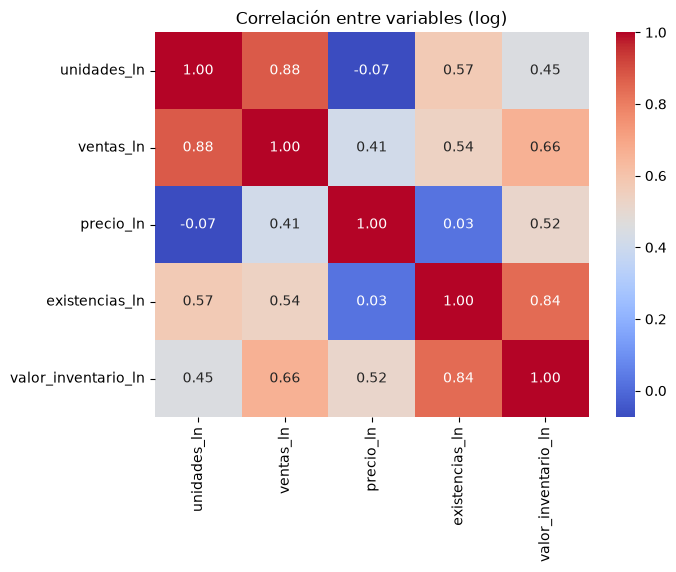

unidades_ln     ventas_ln              0.876975
existencias_ln  valor_inventario_ln    0.844724
ventas_ln       valor_inventario_ln    0.661959
dtype: float64
               coef   error         t  p_valor  ic_inf  ic_sup
const        6.5694  0.0368  178.3823      0.0  6.4971  6.6416
unidades_ln  0.9491  0.0153   62.1304      0.0  0.9191  0.9790
R2: 0.7691


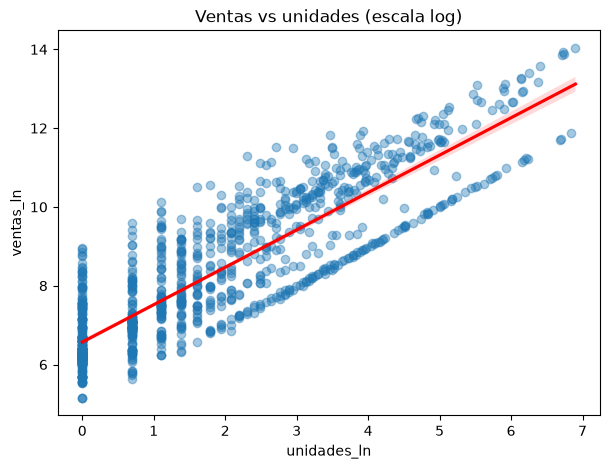

In [15]:
# función para mostrar los coeficientes en una tabla limpia
def tabla_coef(modelo):
    t = pd.DataFrame({'coef': modelo.params, 'error': modelo.bse,
                      't': modelo.tvalues, 'p_valor': modelo.pvalues})
    t['ic_inf'] = modelo.conf_int()[0]
    t['ic_sup'] = modelo.conf_int()[1]
    return t.round(4)

matriz_corr = base_ln.corr()
plt.figure(figsize=(7, 5))
sns.heatmap(matriz_corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlación entre variables (log)')
plt.show()

# pares ordenados de mayor a menor correlación
ranking_corr = matriz_corr.where(np.triu(np.ones(matriz_corr.shape), 1).astype(bool)).stack().sort_values(ascending=False)
print(ranking_corr.head(3))

mod_simple = sm.OLS(base_ln['ventas_ln'], sm.add_constant(base_ln[['unidades_ln']])).fit()
print(tabla_coef(mod_simple))
print('R2:', round(mod_simple.rsquared, 4))

plt.figure(figsize=(7, 5))
sns.regplot(x='unidades_ln', y='ventas_ln', data=base_ln,
            scatter_kws={'alpha': 0.4}, line_kws={'color': 'red'})
plt.title('Ventas vs unidades (escala log)')
plt.show()

In [16]:
# primero reviso multicolinealidad con VIF
predictores = base_ln.drop(columns='ventas_ln')
tabla_vif = pd.Series([variance_inflation_factor(sm.add_constant(predictores).values, i + 1)
                       for i in range(predictores.shape[1])], index=predictores.columns)
print(tabla_vif.round(2))

# existencias y valor_inventario tienen VIF alto y no salen significativas, las saco
vars_finales = ['unidades_ln', 'precio_ln']
mod_multiple = sm.OLS(base_ln['ventas_ln'], sm.add_constant(base_ln[vars_finales])).fit()
print(tabla_coef(mod_multiple))
print('R2:', round(mod_multiple.rsquared, 4), '| R2 ajustado:', round(mod_multiple.rsquared_adj, 4))

# comparación de coeficientes
pd.DataFrame({'simple': mod_simple.params, 'multiple': mod_multiple.params}).round(4)

unidades_ln             1.52
precio_ln               7.01
existencias_ln         17.92
valor_inventario_ln    24.31
dtype: float64
               coef   error          t  p_valor  ic_inf  ic_sup
const       -0.0269  0.0072    -3.7602   0.0002 -0.0410 -0.0129
unidades_ln  0.9878  0.0006  1778.3457   0.0000  0.9867  0.9889
precio_ln    1.0046  0.0011   938.2098   0.0000  1.0025  1.0067
R2: 0.9997 | R2 ajustado: 0.9997


,simple,multiple
const,6.5694,-0.0269
precio_ln,NaN,1.0046
unidades_ln,0.9491,0.9878


In [17]:
# venta de mayoreo = 5 o más unidades en la línea
df_logit = df_ventas.copy()
df_logit['es_mayoreo'] = (df_logit['total_unidades'] >= 5).astype(int)
df_logit['precio_ln'] = np.log(df_logit['precio_unitario'])
print(df_logit['es_mayoreo'].value_counts(normalize=True).round(3))

X_ent, X_val, y_ent, y_val = train_test_split(df_logit[['precio_ln']], df_logit['es_mayoreo'],
                                              test_size=0.3, stratify=df_logit['es_mayoreo'], random_state=42)

# 1) sin hacer nada
logit_base = LogisticRegression().fit(X_ent, y_ent)
# 2) reponderación de clases
logit_pesos = LogisticRegression(class_weight='balanced').fit(X_ent, y_ent)
# 3) oversampling de la clase minoritaria
ent = pd.concat([X_ent, y_ent], axis=1)
clase_min = ent[ent['es_mayoreo'] == 1]
clase_may = ent[ent['es_mayoreo'] == 0]
clase_min_up = resample(clase_min, replace=True, n_samples=len(clase_may), random_state=42)
ent_bal = pd.concat([clase_may, clase_min_up])
logit_over = LogisticRegression().fit(ent_bal[['precio_ln']], ent_bal['es_mayoreo'])

for nombre, m in [('Sin ajuste', logit_base), ('Reponderación', logit_pesos), ('Oversampling', logit_over)]:
    print(nombre)
    print(classification_report(y_val, m.predict(X_val), zero_division=0))

es_mayoreo
0    0.854
1    0.146
Name: proportion, dtype: float64
Sin ajuste
              precision    recall  f1-score   support

           0       0.85      1.00      0.92      5129
           1       0.00      0.00      0.00       877

    accuracy                           0.85      6006
   macro avg       0.43      0.50      0.46      6006
weighted avg       0.73      0.85      0.79      6006

Reponderación
              precision    recall  f1-score   support

           0       0.89      0.60      0.72      5129
           1       0.19      0.55      0.28       877

    accuracy                           0.59      6006
   macro avg       0.54      0.58      0.50      6006
weighted avg       0.79      0.59      0.65      6006

Oversampling
              precision    recall  f1-score   support

           0       0.89      0.60      0.72      5129
           1       0.19      0.55      0.28       877

    accuracy                           0.59      6006
   macro avg       0.54 

In [18]:
df_logit['marca_vita'] = (df_logit['marc'] == 'VITA').astype(int)
df_logit['marca_aidite'] = (df_logit['marc'] == 'AIDITE').astype(int)
df_logit['edo_cdmx'] = (df_logit['estado'] == 'Ciudad de México').astype(int)
df_logit['edo_puebla'] = (df_logit['estado'] == 'Puebla').astype(int)
df_logit['precio_sobre_mediana'] = (df_logit['precio_unitario'] > df_logit['precio_unitario'].median()).astype(int)

vars_dico = ['marca_vita', 'marca_aidite', 'edo_cdmx', 'edo_puebla', 'precio_sobre_mediana']
X_ent, X_val, y_ent, y_val = train_test_split(df_logit[vars_dico], df_logit['es_mayoreo'],
                                              test_size=0.3, stratify=df_logit['es_mayoreo'], random_state=42)

mod_logit = LogisticRegression(class_weight='balanced').fit(X_ent, y_ent)
y_pred = mod_logit.predict(X_val)
print(classification_report(y_val, y_pred))
print('AUC:', round(roc_auc_score(y_val, mod_logit.predict_proba(X_val)[:, 1]), 3))

# odds ratio para interpretar los coeficientes
pd.DataFrame({'coef': mod_logit.coef_[0], 'odds_ratio': np.exp(mod_logit.coef_[0])},
             index=vars_dico).round(3)

              precision    recall  f1-score   support

           0       0.93      0.52      0.67      5129
           1       0.22      0.78      0.34       877

    accuracy                           0.56      6006
   macro avg       0.58      0.65      0.51      6006
weighted avg       0.83      0.56      0.62      6006

AUC: 0.709


,coef,odds_ratio
marca_vita,-0.992,0.371
marca_aidite,0.426,1.531
edo_cdmx,-1.662,0.190
edo_puebla,-0.107,0.899
precio_sobre_mediana,-1.730,0.177


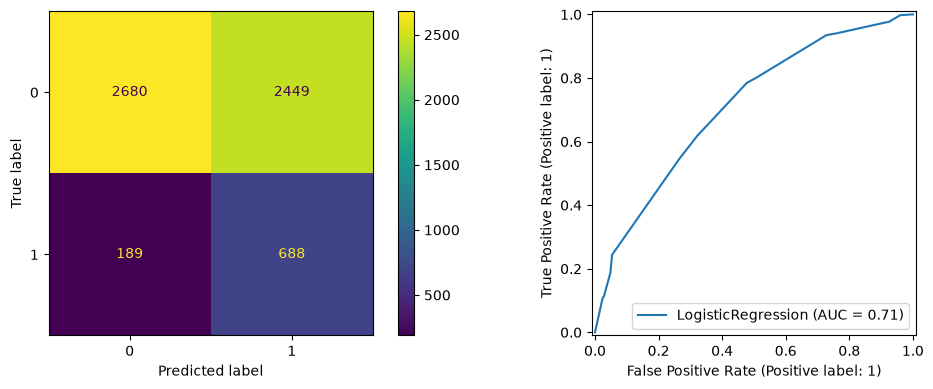

In [19]:
fig, ejes = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay(confusion_matrix(y_val, y_pred)).plot(ax=ejes[0])
RocCurveDisplay.from_estimator(mod_logit, X_val, y_val, ax=ejes[1])
plt.tight_layout()
plt.show()